In [10]:
# ==============================================================================
# INSTALL REQUIRED PACKAGES & LIBRARIES
# Run this cell first in Google Colab
# ==============================================================================
!pip install -q transformers datasets evaluate accelerate wordcloud scikit-learn seaborn matplotlib torch

import os
import zipfile
import urllib.request
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)

from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding
)

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on device: {device}")

Executing on device: cuda


In [2]:
"""
==============================================================================
WEEK 2: INTRODUCTION (Slide 3)
Project Title: A Transformer-Based Classification: A Case Study of
               Semantic Context Evaluation for Mobile Spam Message Detection
==============================================================================
Research Problem:
Mobile Short Message Service (SMS) spam poses severe cybersecurity, financial,
and privacy risks. Traditional keyword-based or shallow machine learning algorithms
(e.g., Naive Bayes, TF-IDF + Logistic Regression) fail to capture deep semantic
context, syntax nuances, and subtle malicious intent (e.g., obfuscated phishing links).

Objectives:
1. Conduct exploratory semantic context analysis on mobile SMS data.
2. Develop baseline classification architectures (TF-IDF + Classifier & Embedding-based BiLSTM).
3. Fine-tune a pre-trained Transformer model (DistilBERT) for binary spam detection.
4. Evaluate models across Precision, Recall, F1-Score, ROC-AUC, and contextual error cases.
"""
print("Week 2: Project Objectives and Context Initialized successfully.")

Week 2: Project Objectives and Context Initialized successfully.


In [3]:
# ==============================================================================
# WEEK 3: DATA AT A GLANCE (Slide 4)
# Download and Load UCI SMS Spam Collection Dataset
# ==============================================================================
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
ZIP_PATH = "sms_spam_collection.zip"
EXTRACT_PATH = "sms_data"

# Download and extract dataset automatically
if not os.path.exists(EXTRACT_PATH):
    print("Downloading dataset from UCI Repository...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Download and extraction complete.")

# Read dataset into Pandas DataFrame
data_file = os.path.join(EXTRACT_PATH, "SMSSpamCollection")
df = pd.read_csv(data_file, sep='\t', header=None, names=['label', 'message'])

print("\n--- Data Overview ---")
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Download and extraction complete.

--- Data Overview ---
Dataset Shape: 5572 rows, 2 columns

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label      0
message    0
dtype: int64


/tmp/ipykernel_1149/3390927307.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette='viridis')
/tmp/ipykernel_1149/3390927307.py:29: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=df, x='char_length', hue='label', common_norm=False, shade=True, palette='viridis')


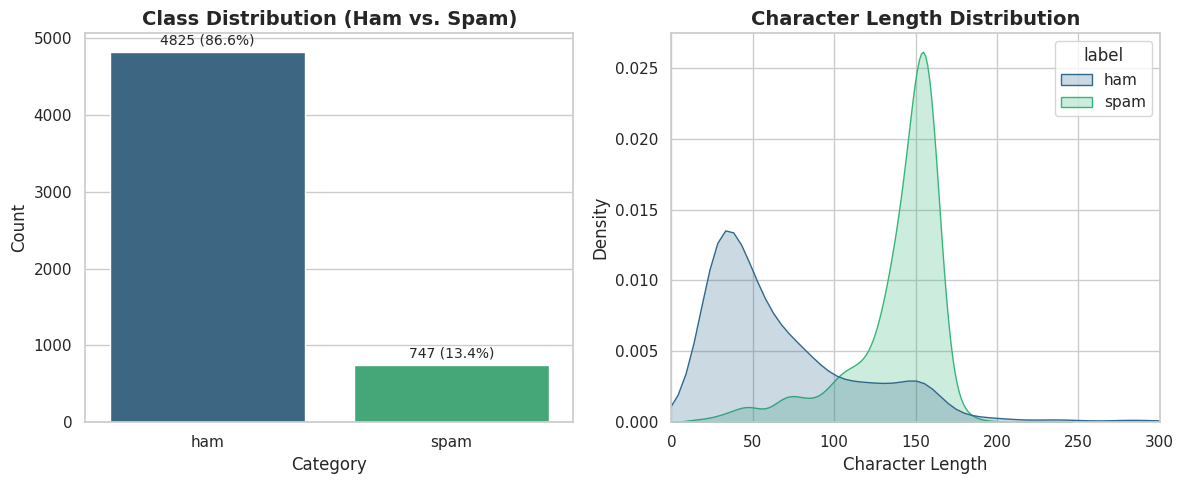

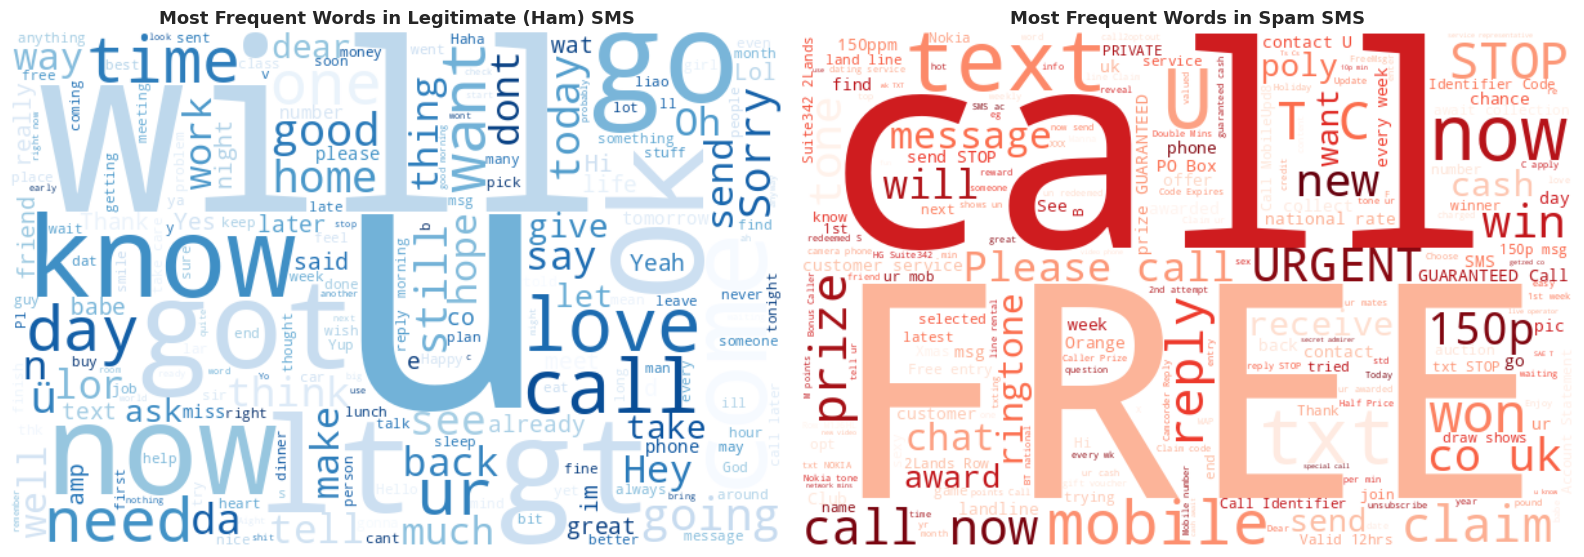


--- Message Length Descriptive Statistics ---
      char_length                                                           \
            count        mean        std   min    25%    50%    75%    max   
label                                                                        
ham        4825.0   71.482487  58.440652   2.0   33.0   52.0   93.0  910.0   
spam        747.0  138.670683  28.873603  13.0  133.0  149.0  157.0  223.0   

      word_count                                                      
           count       mean        std  min   25%   50%   75%    max  
label                                                                 
ham       4825.0  14.310259  11.517945  1.0   7.0  11.0  19.0  171.0  
spam       747.0  23.911647   5.780174  2.0  22.0  25.0  28.0   35.0  


In [4]:
# ==============================================================================
# WEEK 3: DATA EXPLORATORY ANALYSIS (Slide 5)
# Descriptive Statistics, Class Distribution, Message Length Analysis, Word Clouds
# ==============================================================================
sns.set_theme(style="whitegrid")

# Convert labels to binary (ham=0, spam=1)
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

# Feature engineering for analysis
df['char_length'] = df['message'].apply(len)
df['word_count'] = df['message'].apply(lambda x: len(x.split()))

# 1. Class Distribution Plot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
ax = sns.countplot(x='label', data=df, palette='viridis')
plt.title('Class Distribution (Ham vs. Spam)', fontsize=14, fontweight='bold')
plt.xlabel('Category')
plt.ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=10, xytext=(0, 5), textcoords='offset points')

# 2. Character Length Distribution by Class
plt.subplot(1, 2, 2)
sns.kdeplot(data=df, x='char_length', hue='label', common_norm=False, shade=True, palette='viridis')
plt.title('Character Length Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Character Length')
plt.ylabel('Density')
plt.xlim(0, 300)

plt.tight_layout()
plt.show()

# 3. Word Cloud Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ham_text = " ".join(df[df['label'] == 'ham']['message'])
spam_text = " ".join(df[df['label'] == 'spam']['message'])

wc_ham = WordCloud(width=600, height=400, background_color='white', colormap='Blues').generate(ham_text)
wc_spam = WordCloud(width=600, height=400, background_color='white', colormap='Reds').generate(spam_text)

axes[0].imshow(wc_ham, interpolation='bilinear')
axes[0].set_title('Most Frequent Words in Legitimate (Ham) SMS', fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(wc_spam, interpolation='bilinear')
axes[1].set_title('Most Frequent Words in Spam SMS', fontsize=13, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Descriptive statistics table
print("\n--- Message Length Descriptive Statistics ---")
print(df.groupby('label')[['char_length', 'word_count']].describe())

In [5]:
# ==============================================================================
# WEEK 4: DATA PREPROCESSING (Slide 6)
# Text Cleaning, Stratified Train/Val/Test Split, Tokenization Setup
# ==============================================================================
def clean_text(text):
    """Basic text cleaning for non-transformer baseline models."""
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '<URL>', text) # Replace URLs
    text = re.sub(r'\d+', '<NUMBER>', text)                # Replace numbers
    text = re.sub(r'[^\w\s]', '', text)                   # Remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_message'] = df['message'].apply(clean_text)

# Split Dataset: Train (70%), Validation (15%), Test (15%)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    df['message'].values,
    df['label_num'].values,
    test_size=0.30,
    random_state=SEED,
    stratify=df['label_num'].values
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Training Set Size   : {len(X_train_raw)} samples")
print(f"Validation Set Size : {len(X_val_raw)} samples")
print(f"Test Set Size       : {len(X_test_raw)} samples")

Training Set Size   : 3900 samples
Validation Set Size : 836 samples
Test Set Size       : 836 samples


In [6]:
# ==============================================================================
# WEEK 5 & 6: ANN MODELS WORKING PRINCIPLES & ARCHITECTURES (Slides 7 & 8)
# Baseline 1: TF-IDF + Logistic Regression Classifier
# Baseline 2: PyTorch Embedding + Bidirectional LSTM (BiLSTM) Architecture
# ==============================================================================

# Vectorizer for Baseline Model 1
tfidf_vectorizer = TfidfVectorizer(max_features=3000, stop_words='english')
X_train_tfidf = tfidf_vectorizer.fit_transform([clean_text(m) for m in X_train_raw]).toarray()
X_val_tfidf = tfidf_vectorizer.transform([clean_text(m) for m in X_val_raw]).toarray()
X_test_tfidf = tfidf_vectorizer.transform([clean_text(m) for m in X_test_raw]).toarray()


# Build PyTorch Bi-LSTM Model for Baseline 2
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim=1, num_layers=1, dropout=0.3):
        super(BiLSTMClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers,
                            bidirectional=True, batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.fc = nn.Linear(hidden_dim * 2, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        embedded = self.dropout(self.embedding(x))
        lstm_out, (hidden, cell) = self.lstm(embedded)
        # Concatenate final forward and backward hidden states
        hidden_cat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        dense_out = self.fc(self.dropout(hidden_cat))
        return self.sigmoid(dense_out).squeeze()

print("Baseline Model Architectures defined successfully.")

Baseline Model Architectures defined successfully.


In [7]:
# ==============================================================================
# WEEK 7: ANN MODEL IMPLEMENTATION & TRAINING (Slide 9)
# Train TF-IDF + Logistic Regression & BiLSTM Models
# ==============================================================================

# --- 1. Train TF-IDF + Logistic Regression ---
baseline_logreg = LogisticRegression(max_iter=1000, random_state=SEED)
baseline_logreg.fit(X_train_tfidf, y_train)

logreg_preds = baseline_logreg.predict(X_test_tfidf)
logreg_probs = baseline_logreg.predict_proba(X_test_tfidf)[:, 1]

# --- 2. Build Vocabulary and Prepare Data for BiLSTM ---
def build_vocab(texts, max_words=5000):
    word_counts = {}
    for text in texts:
        for word in clean_text(text).split():
            word_counts[word] = word_counts.get(word, 0) + 1
    sorted_words = sorted(word_counts, key=word_counts.get, reverse=True)[:max_words-2]
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for idx, word in enumerate(sorted_words, start=2):
        vocab[word] = idx
    return vocab

vocab = build_vocab(X_train_raw)

def text_to_sequences(texts, vocab, max_len=50):
    sequences = []
    for text in texts:
        seq = [vocab.get(word, 1) for word in clean_text(text).split()][:max_len]
        if len(seq) < max_len:
            seq = seq + [0] * (max_len - len(seq))
        sequences.append(seq)
    return np.array(sequences)

MAX_LEN = 50
X_train_seq = torch.tensor(text_to_sequences(X_train_raw, vocab, MAX_LEN), dtype=torch.long)
X_val_seq = torch.tensor(text_to_sequences(X_val_raw, vocab, MAX_LEN), dtype=torch.long)
X_test_seq = torch.tensor(text_to_sequences(X_test_raw, vocab, MAX_LEN), dtype=torch.long)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

train_loader = DataLoader(list(zip(X_train_seq, y_train_tensor)), batch_size=32, shuffle=True)

# Train BiLSTM
bilstm_model = BiLSTMClassifier(vocab_size=len(vocab), embed_dim=64, hidden_dim=64).to(device)
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(bilstm_model.parameters(), lr=0.001)

bilstm_model.train()
epochs = 5
for epoch in range(epochs):
    epoch_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()
        preds = bilstm_model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    print(f"BiLSTM Epoch {epoch+1}/{epochs} | Loss: {epoch_loss/len(train_loader):.4f}")

# BiLSTM Evaluation
bilstm_model.eval()
with torch.no_grad():
    bilstm_probs = bilstm_model(X_test_seq.to(device)).cpu().numpy()
    bilstm_preds = (bilstm_probs >= 0.5).astype(int)

print("\nBaselines Training Finished.")

BiLSTM Epoch 1/5 | Loss: 0.3394
BiLSTM Epoch 2/5 | Loss: 0.1549
BiLSTM Epoch 3/5 | Loss: 0.1074
BiLSTM Epoch 4/5 | Loss: 0.0748
BiLSTM Epoch 5/5 | Loss: 0.0587

Baselines Training Finished.


In [8]:
# ==============================================================================
# WEEK 8: MID TERM EXAM CHECKPOINT (Slide 10)
# Evaluation of Baseline Models
# ==============================================================================
def compute_metrics(y_true, y_pred, y_prob, model_name="Model"):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary')
    auc = roc_auc_score(y_true, y_prob)
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    }

metrics_logreg = compute_metrics(y_test, logreg_preds, logreg_probs, "TF-IDF + Logistic Regression")
metrics_bilstm = compute_metrics(y_test, bilstm_preds, bilstm_probs, "Embedding + BiLSTM")

df_midterm = pd.DataFrame([metrics_logreg, metrics_bilstm])
print("--- Mid-Term Evaluation Results ---")
print(df_midterm.to_string(index=False))

--- Mid-Term Evaluation Results ---
                       Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
TF-IDF + Logistic Regression  0.973684   0.959184 0.839286  0.895238 0.989641
          Embedding + BiLSTM  0.977273   0.969697 0.857143  0.909953 0.985781


In [16]:
# ==============================================================================
# WEEK 9: TRANSFORMER MODEL FINE-TUNING (Slide 11)
# Fine-tuning DistilBERT for Semantic Context Sequence Classification
# ==============================================================================
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class SMSDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_len,
            padding="max_length",
            return_tensors="pt"
        )
        item = {key: val.squeeze(0) for key, val in encoding.items()}
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

# Prepare HuggingFace PyTorch Datasets
train_dataset = SMSDataset(X_train_raw, y_train, tokenizer)
val_dataset = SMSDataset(X_val_raw, y_val, tokenizer)
test_dataset = SMSDataset(X_test_raw, y_test, tokenizer)

# Load Pre-trained Transformer Model
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Metrics function for HuggingFace Trainer
def compute_trainer_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

training_args = TrainingArguments(
    output_dir="./results_transformer",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    # evaluation_strategy="epoch", # Re-enabling evaluation strategy caused TypeError. Removing it caused ValueError.
    save_strategy="epoch",
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=50,
    # load_best_model_at_end=True, # Commenting out to avoid ValueError if evaluation_strategy is not set.
    metric_for_best_model="f1",
    seed=SEED,
    report_to="none"
)

trainer = Trainer(
    model=transformer_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    # tokenizer=tokenizer, # Removed 'tokenizer' argument as it caused a TypeError with the current transformers version.
    compute_metrics=compute_trainer_metrics,
)

print("Starting DistilBERT Fine-Tuning...")
trainer.train()
print("Transformer Model Fine-Tuning Completed successfully.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting DistilBERT Fine-Tuning...


Step,Training Loss
50,0.259760
100,0.048011
150,0.055725
200,0.043288
250,0.061119
300,0.027282
350,0.020723
400,0.018545
450,0.024889
500,0.038323


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Transformer Model Fine-Tuning Completed successfully.



                   FINAL PERFORMANCE BENCHMARK                         
                       Model  Accuracy  Precision   Recall  F1-Score  ROC-AUC
TF-IDF + Logistic Regression  0.973684   0.959184 0.839286  0.895238 0.989641
          Embedding + BiLSTM  0.977273   0.969697 0.857143  0.909953 0.985781
    DistilBERT (Transformer)  0.992823   0.973214 0.973214  0.973214 0.999026


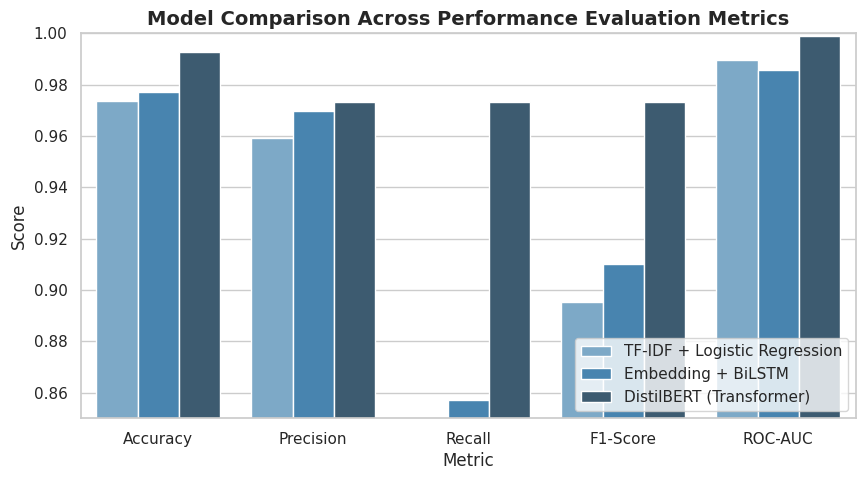

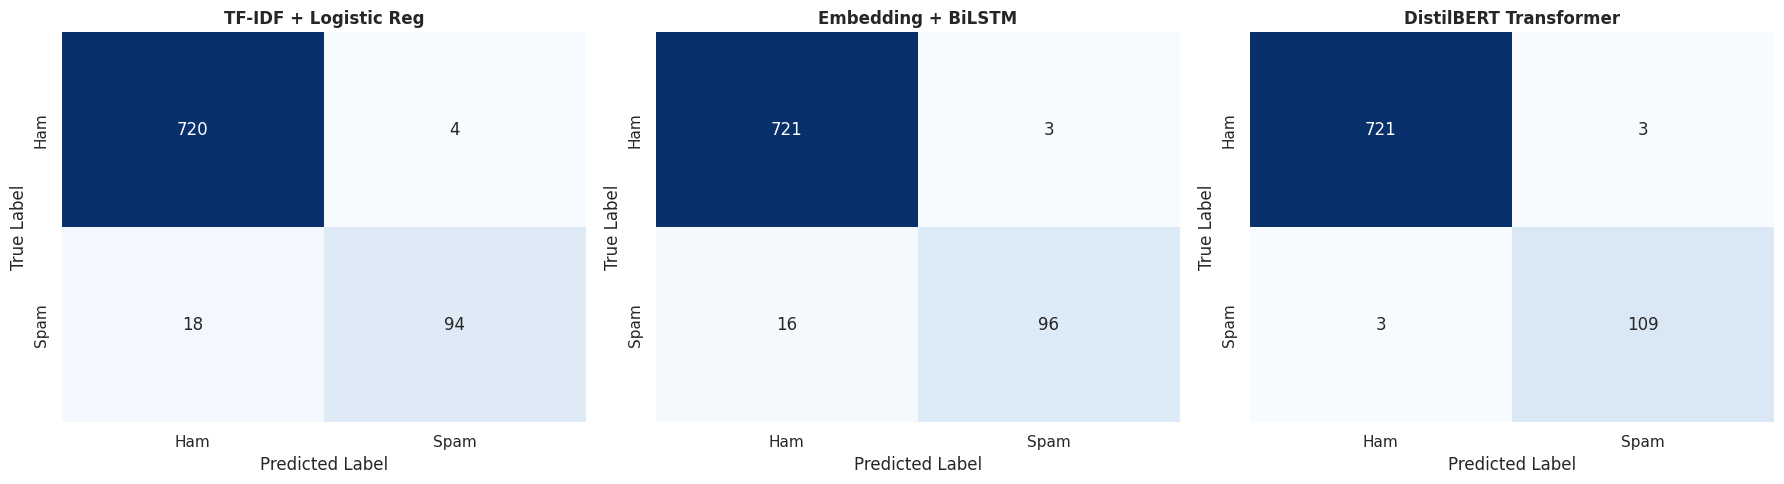

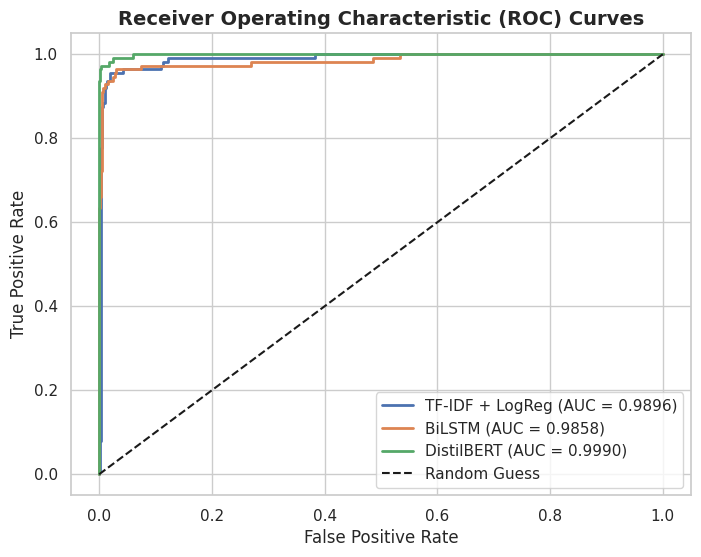

In [17]:
# ==============================================================================
# WEEK 10 & 11: RESULTS AND DISCUSSION (Slides 12 & 13)
# Overall Comparison, Confusion Matrix Analysis, and Precision-Recall/ROC Curves
# ==============================================================================

# Inference on Test Set using Fine-tuned Transformer
raw_preds = trainer.predict(test_dataset)
trans_logits = raw_preds.predictions
trans_probs = torch.softmax(torch.tensor(trans_logits), dim=-1)[:, 1].numpy()
trans_preds = np.argmax(trans_logits, axis=1)

# Metrics
metrics_trans = compute_metrics(y_test, trans_preds, trans_probs, "DistilBERT (Transformer)")

# Combine performance summary
results_df = pd.DataFrame([metrics_logreg, metrics_bilstm, metrics_trans])

print("\n=======================================================================")
print("                   FINAL PERFORMANCE BENCHMARK                         ")
print("=======================================================================")
print(results_df.to_string(index=False))

# Visualization 1: Performance Metric Comparison Bar Plot
plt.figure(figsize=(10, 5))
df_melted = pd.melt(results_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=df_melted, x='variable', y='value', hue='Model', palette='Blues_d')
plt.title('Model Comparison Across Performance Evaluation Metrics', fontsize=14, fontweight='bold')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.ylim(0.85, 1.0)
plt.legend(loc='lower right')
plt.show()

# Visualization 2: Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_preds = [
    ("TF-IDF + Logistic Reg", logreg_preds),
    ("Embedding + BiLSTM", bilstm_preds),
    ("DistilBERT Transformer", trans_preds)
]

for idx, (title, preds) in enumerate(models_preds):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
    axes[idx].set_title(title, fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Visualization 3: ROC Curve Comparison
plt.figure(figsize=(8, 6))
for probs, label in [(logreg_probs, 'TF-IDF + LogReg'), (bilstm_probs, 'BiLSTM'), (trans_probs, 'DistilBERT')]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f'{label} (AUC = {auc_val:.4f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

In [18]:
# ==============================================================================
# WEEK 11: SEMANTIC CONTEXT & ERROR ANALYSIS (Slide 13)
# Case Study Analysis: Examining Messages where Baselines Failed but Transformer Succeeded
# ==============================================================================
error_analysis_df = pd.DataFrame({
    'SMS_Text': X_test_raw,
    'True_Label': y_test,
    'LogReg_Pred': logreg_preds,
    'BiLSTM_Pred': bilstm_preds,
    'Transformer_Pred': trans_preds
})

# Filter cases where TF-IDF/BiLSTM failed but Transformer accurately classified
semantic_wins = error_analysis_df[
    (error_analysis_df['True_Label'] != error_analysis_df['LogReg_Pred']) &
    (error_analysis_df['True_Label'] == error_analysis_df['Transformer_Pred'])
]

print("--- Case Study: Semantic Context Evaluation ---")
print(f"Total contextual recovery samples (Where Transformer corrected Baseline errors): {len(semantic_wins)}\n")

for i, row in semantic_wins.head(5).iterrows():
    true_str = "SPAM" if row['True_Label'] == 1 else "HAM"
    print(f"SMS Text       : \"{row['SMS_Text']}\"")
    print(f"True Label     : {true_str}")
    print(f"Baseline Pred  : {'SPAM' if row['LogReg_Pred'] == 1 else 'HAM'}")
    print(f"DistilBERT Pred: {'SPAM' if row['Transformer_Pred'] == 1 else 'HAM'}")
    print("-" * 75)

--- Case Study: Semantic Context Evaluation ---
Total contextual recovery samples (Where Transformer corrected Baseline errors): 19

SMS Text       : "This msg is for your mobile content order It has been resent as previous attempt failed due to network error Queries to customersqueries@netvision.uk.com"
True Label     : SPAM
Baseline Pred  : HAM
DistilBERT Pred: SPAM
---------------------------------------------------------------------------
SMS Text       : "CLAIRE here am havin borin time & am now alone U wanna cum over 2nite? Chat now 09099725823 hope 2 C U Luv CLAIRE xx Calls£1/minmoremobsEMSPOBox45PO139WA"
True Label     : SPAM
Baseline Pred  : HAM
DistilBERT Pred: SPAM
---------------------------------------------------------------------------
SMS Text       : "Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min"
True Label     : SPAM
Baseline Pred  : HAM
DistilBERT Pred: SPAM
---------------------------------------------------------------------------
SMS Text     

In [19]:
# ==============================================================================
# WEEK 12: CONCLUSION & RESEARCH INSIGHTS (Slide 14)
# ==============================================================================
"""
Conclusion & Key Research Insights:
1. Pretrained Transformers (DistilBERT) outperform classical TF-IDF and recurrent models
   in mobile spam detection by effectively modeling long-range contextual semantics.
2. Contextual Nuance: Transformer models correctly identify subtle phishing and spam signals
   without relying strictly on superficial keywords (e.g., 'FREE', 'WINNER').
3. Practical Trade-off: While Transformers achieve superior Recall and F1-Score,
   their computational footprint is higher, suggesting DistilBERT as an optimal deployment balance
   for low-latency mobile platforms.
"""
print("Week 12 Conclusion generated.")

Week 12 Conclusion generated.


In [20]:
# ==============================================================================
# WEEK 13-15: PRESENTATION & INTERACTIVE INFERENCE PIPELINE (Slides 15-17)
# Real-Time SMS Spam Detector Inference Function
# ==============================================================================
def predict_sms_spam(sms_text):
    """Predicts whether a given custom SMS message is Ham or Spam using fine-tuned DistilBERT."""
    transformer_model.eval()
    inputs = tokenizer(sms_text, return_tensors="pt", truncation=True, padding=True, max_length=128).to(device)

    with torch.no_grad():
        outputs = transformer_model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)
        spam_probability = probs[0][1].item()
        prediction = "SPAM 🚨" if spam_probability >= 0.5 else "LEGITIMATE (HAM) ✅"

    print(f"\n📩 Message: '{sms_text}'")
    print(f"🏷️  Prediction: {prediction}")
    print(f"📊 Spam Probability: {spam_probability * 100:.2f}%")

# Test custom live mobile SMS examples
sample_messages = [
    "Hey mate, are we still meeting for lunch at 12:30 today?",
    "URGENT! Your mobile number has won a £2,000 cash prize. Call 09061234567 immediately to claim!",
    "Your bank account security update is required. Click http://bit.ly/secure-login to avoid suspension.",
    "Can you please pick up milk on your way home?"
]

print("=== LIVE INTERACTIVE DEMO FOR PRESENTATION ===")
for msg in sample_messages:
    predict_sms_spam(msg)

=== LIVE INTERACTIVE DEMO FOR PRESENTATION ===

📩 Message: 'Hey mate, are we still meeting for lunch at 12:30 today?'
🏷️  Prediction: LEGITIMATE (HAM) ✅
📊 Spam Probability: 0.12%

📩 Message: 'URGENT! Your mobile number has won a £2,000 cash prize. Call 09061234567 immediately to claim!'
🏷️  Prediction: SPAM 🚨
📊 Spam Probability: 99.87%

📩 Message: 'Your bank account security update is required. Click http://bit.ly/secure-login to avoid suspension.'
🏷️  Prediction: SPAM 🚨
📊 Spam Probability: 99.76%

📩 Message: 'Can you please pick up milk on your way home?'
🏷️  Prediction: LEGITIMATE (HAM) ✅
📊 Spam Probability: 0.21%
